# 02 – Régi hírek: besorolás, H1a és validáció

Szakdolgozat: 4.6 (újdonságmérés), 4.10.1 (H1a), 5.2 (validáció), 5.3 (a régi hírek aránya).

**H1a.** A vizsgált időszakban megjelent részvényspecifikus portálhírek jelentős hányada régi hírt közöl.
*Döntési szabály:* elfogadom, ha a rétegzett  kézim imntán becsült arány 95%-os konfidenciaintervallumának alsó határa 50% felett van.

| | |
|---|---|
| **Bemenet** | `korpusz.sqlite` – `dokumentum`, `hivatkozas`; `h1a_validacio.xlsx` (kézi címkék) |
| **Kimenet** | `adat/cache/regi_hir.parquet` (cikk×ticker páronként az osztály; a 03. és a 04. notebook olvassa); a kézi címkézés munkafüzete, ha még nem létezik |
| **Módszer** | Fedyk és Hodson (2023); Cohen (1960) kappa; rétegzett, cikkszintű klaszter-bootstrap |

## 1. Beállítások

In [1]:
import os
import re
import sys
import json
import math
import sqlite3
from pathlib import Path
from datetime import datetime
from collections import Counter, defaultdict
from bisect import bisect_left

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import snowballstemmer
from scipy.stats import rankdata
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PROJEKT = Path(os.environ.get("PROJEKT_MAPPA", Path.cwd()))
DB = PROJEKT / "adat" / "korpusz.sqlite"
CACHE = Path(os.environ.get("CACHE_MAPPA", PROJEKT / "adat" / "cache"))
VALIDACIOS_FAJL = CACHE / "h1a_validacio.xlsx"

sys.path.insert(0, str(PROJEKT))
import közös as KÖ
import konfiguracio as K


def db_kapcsolat():
    con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)
    con.row_factory = sqlite3.Row
    return con

| paraméter | jelentése | értéke |
|---|---|---|
| `REGI_ABLAK_ORA` | az összevetés időablaka (óra) | 72 |
| `REGI_SZOMSZED_DB` | a legtöbb közös szótővel rendelkező korábbi dokumentumok száma | 5 |
| `REGI_KUSZOB` | Old-küszöb: ettől régi a hír | 0,60 |
| `REGI_ATVETEL_KUSZOB` | Closest/Old-küszöb: efölött átvétel, alatta újrakombinálás | 0,80 |
| `REGI_MIN_SZO` | ennél kevesebb szótőből álló cikk nem kerül besorolásra | 10 |
| `N_MINTA` | a kézi minta elemszáma | 400 |
| `SEED` | a véletlenszám-generátor magja | 42 |
| `BOOTSTRAP` | bootstrap-ismétlések száma | 5 000 |

In [2]:
REGI_ABLAK_ORA = 72
REGI_SZOMSZED_DB = 5
REGI_KUSZOB = 0.60
REGI_ATVETEL_KUSZOB = 0.80
REGI_MIN_SZO = 10
N_MINTA = 400
SEED = 42
BOOTSTRAP = 5000

## 2. Szótő-halmazok (4.6)

- cím + lead + törzs, kisbetűsítés, szavakra bontás, magyar stopszavak elhagyása;
- Snowball magyar szótövező; a számok és a négy cégnév változatlanul maradnak;
- BÉT-közleményeknél a fejléc, a csatolmánylista és az elérhetőségek törlése (`közös.bet_szoveg_tisztit`);
- tickerek: `ticker_eros` (cím/lead) és `ticker_gyenge` (csak törzsszöveg).

In [3]:
TOKEN = re.compile(r"[^\W_]+")
TOVEZO = snowballstemmer.stemmer("hungarian")
TOVEK = {}
CEGNEVEK = frozenset(["telekom", "richter", "otp", "mol"])
STOPSZAVAK = frozenset("""a az egy és hogy is nem de van volt lesz lett már még meg el ki be fel le át
ez ezt ezek az azt azok ami amely amelyek amit aki mint vagy ha csak által szerint után előtt
között alatt felé során illetve valamint ezzel azzal ebben abban erre arra ide oda itt ott
így úgy miatt ellen óta is sem se mert mivel ezért azért pedig viszont azonban tehát
én te ő mi ti ők őket nekik neki nekem vele rá rá ról ről től tól hoz hez höz nak nek ban ben
ra re ba be val vel ért ig kor""".split())

def szotovek(szoveg):
    halmaz = set()
    for t in TOKEN.findall((szoveg or "").lower()):
        if t in STOPSZAVAK:
            continue
        if t.isdigit():
            halmaz.add(t)
            continue
        if len(t) < 2:
            continue
        if t in CEGNEVEK:
            halmaz.add(t)
            continue
        if t not in TOVEK:
            TOVEK[t] = TOVEZO.stemWord(t)
        halmaz.add(TOVEK[t])
    return frozenset(halmaz)


print(sorted(szotovek("A Magyar Telekom 2024-ben 150 forintos osztalékot fizet a részvényeseknek.")))

['150', '2024', 'fiz', 'forintos', 'magyar', 'osztale', 'részvényes', 'telekom']


In [4]:
def idobelyeg(iso):
    return datetime.fromisoformat(iso.replace("Z", "+00:00")).timestamp()


class Dok:
    def __init__(self, sor):
        self.doc_id = sor["doc_id"]
        self.forras = sor["forras"]
        self.ts = idobelyeg(sor["megjelenes_utc"])
        self.kulcs = (self.ts, 0 if self.forras == "bet" else 1, self.doc_id)
        torzs = KÖ.bet_szoveg_tisztit(sor["szoveg"]) if self.forras == "bet" else (sor["szoveg"] or "")
        self.szavak = szotovek(f"{sor['cim'] or ''} {sor['lead'] or ''} {torzs}")
        self.tickerek_eros = sorted(set(json.loads(sor["ticker_eros"] or "[]")))
        gyenge = set(json.loads(sor["ticker_gyenge"] or "[]"))
        self.tickerek = sorted(set(self.tickerek_eros) | gyenge)


con = db_kapcsolat()
dokok = {}
for sor in con.execute("""SELECT doc_id, forras, cim, lead, szoveg, megjelenes_utc, ticker_eros, ticker_gyenge
                          FROM dokumentum WHERE megjelenes_utc IS NOT NULL AND szoveg IS NOT NULL"""):
    d = Dok(sor)
    dokok[d.doc_id] = d
meta = pd.read_sql("SELECT doc_id, forras, cim, lead, url, megjelenes_helyi FROM dokumentum", con).set_index("doc_id")
forras_link = defaultdict(list)
for sor in con.execute("SELECT doc_id, cel_doc_id FROM hivatkozas WHERE tipus = 'forras' AND cel_doc_id IS NOT NULL"):
    forras_link[sor["doc_id"]].append(sor["cel_doc_id"])
con.close()

print(f"{len(dokok)} dokumentum:", dict(Counter(d.forras for d in dokok.values())))
print(f"{len(TOVEK)} különböző szóalak, {len(forras_link)} cikk hivatkozik egy a korpuszban jelen lévő dokumentumra")

4000 dokumentum: {'bet': 1315, 'portfolio': 2366, 'telex': 319}
122946 különböző szóalak, 373 cikk hivatkozik egy a korpuszban jelen lévő dokumentumra


## 3. A besorolási algoritmus (4.6, 1. kódrészlet)

Az $i$ cikk jelöltjei az azonos tickerhez tartozó, a megelőző 72 órában megjelent dokumentumok; ezek közül a legtöbb közös szótővel rendelkező öt ($j_1,\dots,j_5$) marad meg. $W_i$ az $i$ cikk szótő-halmaza:

$$\mathrm{Old}_i=\frac{\left|W_i\cap\bigcup_{k=1}^{5}W_{j_k}\right|}{|W_i|},\qquad \mathrm{Closest}_i=\frac{|W_i\cap W_{j_1}|}{|W_i|}$$

| osztály | feltétel |
|---|---|
| új | $\mathrm{Old}_i<0{,}60$ |
| átvétel | $\mathrm{Old}_i\ge0{,}60$ és $\mathrm{Closest}_i/\mathrm{Old}_i>0{,}80$ |
| újrakombinálás | $\mathrm{Old}_i\ge0{,}60$ és $\mathrm{Closest}_i/\mathrm{Old}_i\le0{,}80$ |

Kiegészítő szabályok:
1. A BÉT-közlemény mindig új; azonos időpontnál a BÉT-közlemény számít korábbinak.
2. Hivatkozás-szabály (Duan és mtsai., 2024): ha a cikk korábbi korpuszbeli dokumentumra hivatkozik, de a szöveg alapján új lenne, régi lesz (egy forrás: átvétel, több: újrakombinálás). Az `osztaly_szoveg` a csak szövegből számolt osztály.
3. A 10 szótőnél rövidebb cikk `rovid` osztályt kap.

In [5]:
def meres(s, jeloltek):
    pontok = []
    for c in jeloltek:
        kozos = len(s.szavak & c.szavak)
        if kozos > 0:
            pontok.append((kozos, c.kulcs, c))
    pontok.sort(key=lambda p: (p[0], p[1]), reverse=True)
    pontok = pontok[:REGI_SZOMSZED_DB]
    if not pontok:
        return 0.0, 0.0, []
    unio = set()
    for _, _, c in pontok:
        unio.update(s.szavak & c.szavak)
    return len(unio) / len(s.szavak), pontok[0][0] / len(s.szavak), [c for _, _, c in pontok]


def osztaly_dont(old, kozeli, kuszob=REGI_KUSZOB, atvetel_kuszob=REGI_ATVETEL_KUSZOB):
    if old < kuszob:
        return "uj"
    if kozeli / old > atvetel_kuszob:
        return "atvetel"
    return "ujrakombinalt"


def ticker_listak(dokok, ticker_mezo="tickerek"):
    listak = defaultdict(list)
    for d in dokok.values():
        for t in getattr(d, ticker_mezo):
            listak[t].append(d)
    for lista in listak.values():
        lista.sort(key=lambda d: d.kulcs)
    return listak


def jeloltek_valasztas(lista, idok, i, ablak_ora=REGI_ABLAK_ORA):
    s = lista[i]
    kezdet = bisect_left(idok, s.ts - ablak_ora * 3600)
    return [c for c in lista[kezdet:i] if c.kulcs < s.kulcs]

In [6]:
def hivatkozott_korabbiak(s):
    return [c_id for c_id in forras_link.get(s.doc_id, []) if c_id in dokok and dokok[c_id].kulcs < s.kulcs]


def osztalyoz(ticker_mezo="tickerek", ablak_ora=REGI_ABLAK_ORA):
    sorok = []
    for ticker, lista in ticker_listak(dokok, ticker_mezo).items():
        idok = [d.ts for d in lista]
        for i, s in enumerate(lista):
            sor = {"doc_id": s.doc_id, "ticker": ticker, "forras": s.forras, "szoveg_db": len(s.szavak),
                   "hivatkozott": "[]", "szomszedok": "[]", "regi_arany": np.nan, "kozeli_arany": np.nan,
                   "jelolt_db": 0, "bet_elozmeny": False}
            if s.forras == "bet":
                sorok.append({**sor, "osztaly": "uj", "osztaly_szoveg": "uj", "indok": "bet"})
                continue
            jeloltek = jeloltek_valasztas(lista, idok, i, ablak_ora)
            sor["jelolt_db"] = len(jeloltek)
            sor["bet_elozmeny"] = any(c.forras == "bet" for c in jeloltek)
            if len(s.szavak) < REGI_MIN_SZO:
                sorok.append({**sor, "osztaly": "rovid", "osztaly_szoveg": "rovid", "indok": "szoveg"})
                continue
            old, kozeli, szomszedok = meres(s, jeloltek)
            szoveg_osztaly = osztaly_dont(old, kozeli)
            osztaly, indok = szoveg_osztaly, "szoveg"
            korabbiak = hivatkozott_korabbiak(s)
            if korabbiak:
                if szoveg_osztaly == "uj":
                    osztaly = "atvetel" if len(korabbiak) == 1 else "ujrakombinalt"
                    indok = "hivatkozas"
                else:
                    indok = "szoveg+hivatkozas"
            sorok.append({**sor, "regi_arany": old, "kozeli_arany": kozeli, "hivatkozott": json.dumps(korabbiak),
                          "szomszedok": json.dumps([c.doc_id for c in szomszedok]),
                          "osztaly": osztaly, "osztaly_szoveg": szoveg_osztaly, "indok": indok})
    return pd.DataFrame(sorok)


regi = osztalyoz()
print(f"{len(regi)} cikk×ticker pár")

7676 cikk×ticker pár


## 4. A besorolás eredménye

In [7]:
display(pd.crosstab(regi.forras, regi.osztaly, margins=True, margins_name="összesen"))
portal = regi[regi.forras != "bet"]
print("A portálos hírek besorolásának indoka:", dict(Counter(portal.indok)))
print(f"A hivatkozás-szabály a portálos hírek {(portal.osztaly != portal.osztaly_szoveg).mean():.1%}-ánál "
      f"változtatta meg a szöveges osztályt.")

osztaly,atvetel,uj,ujrakombinalt,összesen
forras,,,,
bet,0,1315,0,1315
portfolio,2583,1446,2072,6101
telex,62,171,27,260
összesen,2645,2932,2099,7676


A portálos hírek besorolásának indoka: {'szoveg': 5675, 'szoveg+hivatkozas': 284, 'hivatkozas': 402}
A hivatkozás-szabály a portálos hírek 6.3%-ánál változtatta meg a szöveges osztályt.


A cikk x ticker párok ábrázolása

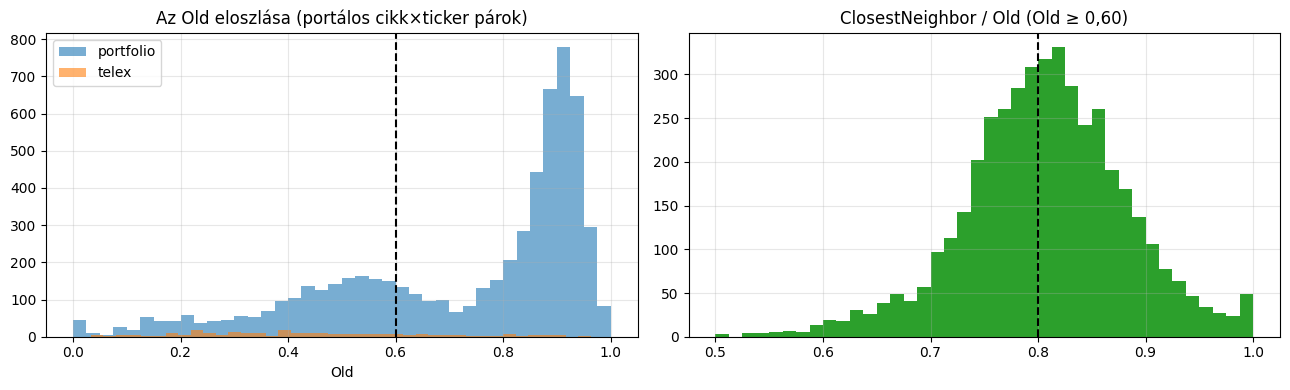

In [8]:
x = portal.dropna(subset=["regi_arany"])
regiek = x[x.regi_arany >= REGI_KUSZOB]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for forras, g in x.groupby("forras"):
    ax[0].hist(g.regi_arany, bins=40, alpha=0.6, label=forras)
ax[0].axvline(REGI_KUSZOB, color="k", ls="--")
ax[0].set_title("Az Old eloszlása (portálos cikk×ticker párok)")
ax[0].set_xlabel("Old")
ax[0].legend()
ax[1].hist(regiek.kozeli_arany / regiek.regi_arany, bins=40, color="C2")
ax[1].axvline(REGI_ATVETEL_KUSZOB, color="k", ls="--")
ax[1].set_title("ClosestNeighbor / Old (Old ≥ 0,60)")
plt.tight_layout()
plt.show()

## 5. Paraméter-érzékenység (14. ábra)

Ablak: 24, 72, 168 óra; Old-küszöb: 0,4–0,75; átvétel-küszöb: 0,7–0,9 (45 változat), a hivatkozás-szabállyal együtt, a besorolt portálos cikk×ticker párokon. Az ábra a 7.6 pontban, a kézi mintán becsült arány intervallumával együtt szerepel.

In [9]:
def kuszob_szerint(tabla, kuszob, atvetel_kuszob):
    szoveg = np.where(tabla.regi_arany < kuszob, "uj",
                      np.where(tabla.kozeli_arany / tabla.regi_arany > atvetel_kuszob, "atvetel", "ujrakombinalt"))
    hivatkozas_db = tabla.hivatkozott.map(lambda h: len(json.loads(h))).to_numpy()
    return np.where((szoveg == "uj") & (hivatkozas_db == 1), "atvetel",
                    np.where((szoveg == "uj") & (hivatkozas_db > 1), "ujrakombinalt", szoveg))


racs = []
for ablak in [24, 72, 168]:
    tabla = osztalyoz(ablak_ora=ablak)
    tabla = tabla[(tabla.forras != "bet") & (tabla.osztaly != "rovid")]
    for kuszob in [0.4, 0.5, 0.6, 0.7, 0.75]:
        for atvetel_kuszob in [0.7, 0.8, 0.9]:
            osztaly = pd.Series(kuszob_szerint(tabla, kuszob, atvetel_kuszob))
            racs.append({"ablak (óra)": ablak, "Old-küszöb": kuszob, "átvétel-küszöb": atvetel_kuszob,
                         "N": len(tabla), "régi %": 100 * osztaly.isin(["atvetel", "ujrakombinalt"]).mean(),
                         "átvétel %": 100 * (osztaly == "atvetel").mean(),
                         "újrakombinált %": 100 * (osztaly == "ujrakombinalt").mean()})
racs = pd.DataFrame(racs)
print("A régi hírek aránya (%) az ablak és az Old-küszöb szerint (az átvétel-küszöb ezt nem befolyásolja):")
display(racs.pivot_table(index="ablak (óra)", columns="Old-küszöb", values="régi %").round(1))

A régi hírek aránya (%) az ablak és az Old-küszöb szerint (az átvétel-küszöb ezt nem befolyásolja):


Old-küszöb,0.40,0.50,0.60,0.70,0.75
ablak (óra),,,,,
24,72.8,67.0,61.3,55.1,51.3
72,89.2,82.6,74.6,68.5,66.4
168,97.5,93.8,86.8,75.5,72.5


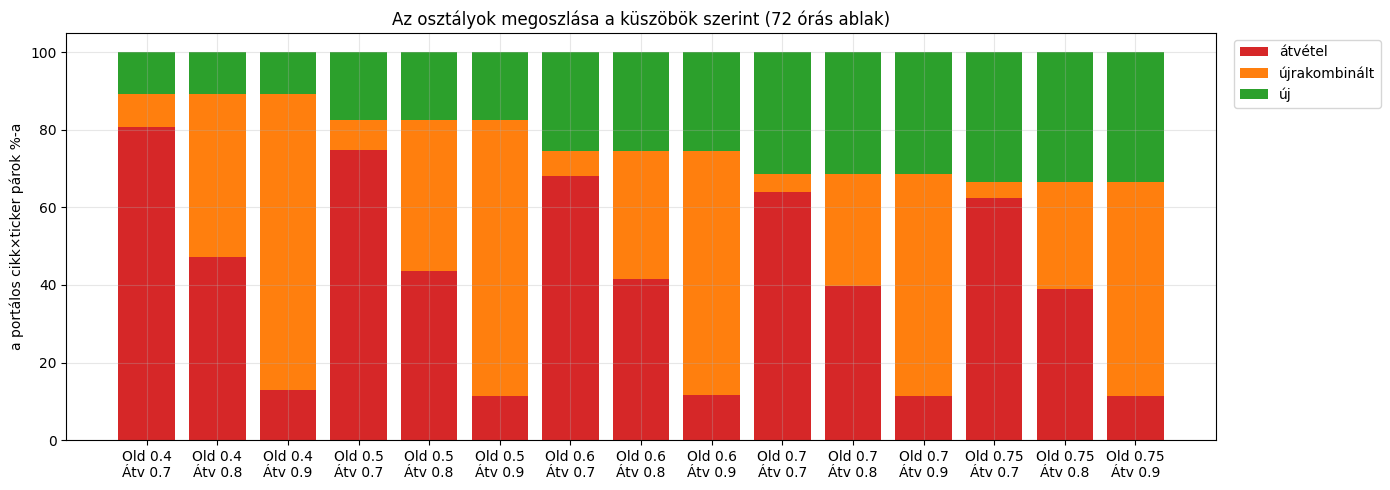

In [10]:
abra = racs[racs["ablak (óra)"] == REGI_ABLAK_ORA].sort_values(["Old-küszöb", "átvétel-küszöb"])
cimkek = [f"Old {o}\nÁtv {a}" for o, a in zip(abra["Old-küszöb"], abra["átvétel-küszöb"])]
fig, ax = plt.subplots(figsize=(14, 5))
alap = np.zeros(len(abra))
for oszlop, szin in [("átvétel %", "C3"), ("újrakombinált %", "C1")]:
    ax.bar(range(len(abra)), abra[oszlop], bottom=alap, color=szin, label=oszlop.replace(" %", ""))
    alap += abra[oszlop].to_numpy()
ax.bar(range(len(abra)), 100 - alap, bottom=alap, color="C2", label="új")
ax.set_xticks(range(len(abra)))
ax.set_xticklabels(cimkek)
ax.set_ylabel("a portálos cikk×ticker párok %-a")
ax.set_title(f"Az osztályok megoszlása a küszöbök szerint ({REGI_ABLAK_ORA} órás ablak)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [11]:
eros = osztalyoz(ticker_mezo="tickerek_eros")
eros_portal = eros[(eros.forras != "bet") & (eros.osztaly != "rovid")]
osszes_portal = regi[(regi.forras != "bet") & (regi.osztaly != "rovid")]
display(pd.DataFrame({
    "N (portálos pár)": [len(osszes_portal), len(eros_portal)],
    "régi %": [100 * osszes_portal.osztaly.isin(["atvetel", "ujrakombinalt"]).mean(),
               100 * eros_portal.osztaly.isin(["atvetel", "ujrakombinalt"]).mean()],
}, index=["erős és gyenge kapcsolat (fő)", "csak erős kapcsolat"]).round(1))

,N (portálos pár),régi %
erős és gyenge kapcsolat (fő),6361,74.6
csak erős kapcsolat,1808,50.5


## 6. Mentés

Az alapparaméterekkel (72 óra; 0,60; 0,80; erős és gyenge ticker-kapcsolat) készült besorolás.

In [12]:
regi.to_parquet(CACHE / "regi_hir.parquet", index=False)
print("Elmentve: regi_hir.parquet")

Elmentve: regi_hir.parquet


## 7. H1a: a régi hírek aránya (4.10.1, 5.3)

### 7.1 A nevező

A Portfolio és a Telex besorolt cikk×ticker párjai (BÉT-közlemények nélkül). Kiegészítő bontás: a 72 órán belül BÉT-közleményt követő párok.

In [13]:
alapsokasag = regi[(regi.forras != "bet") & (regi.osztaly != "rovid")].copy()
alapsokasag["regi_alg"] = alapsokasag.osztaly.isin(["atvetel", "ujrakombinalt"]).astype(int)
N_h = alapsokasag.groupby("forras").size()
p_alg = alapsokasag.regi_alg.mean()
print("A nevező (portálos cikk×ticker párok):", N_h.to_dict(), "összesen:", N_h.sum())
print(f"Az algoritmus szerinti régi arány a teljes állományon: p_alg = {p_alg:.3f}")
print("Rétegenként:", alapsokasag.groupby("forras").regi_alg.mean().round(3).to_dict())
bet_utan = alapsokasag[alapsokasag.bet_elozmeny]
print(f"BÉT-közleményt követő párok: {len(bet_utan)} ({len(bet_utan) / len(alapsokasag):.1%}), "
      f"ezek közül az algoritmus szerint régi: {bet_utan.regi_alg.mean():.3f}")

A nevező (portálos cikk×ticker párok): {'portfolio': 6101, 'telex': 260} összesen: 6361
Az algoritmus szerinti régi arány a teljes állományon: p_alg = 0.746
Rétegenként: {'portfolio': 0.763, 'telex': 0.342}
BÉT-közleményt követő párok: 3541 (55.7%), ezek közül az algoritmus szerint régi: 0.779


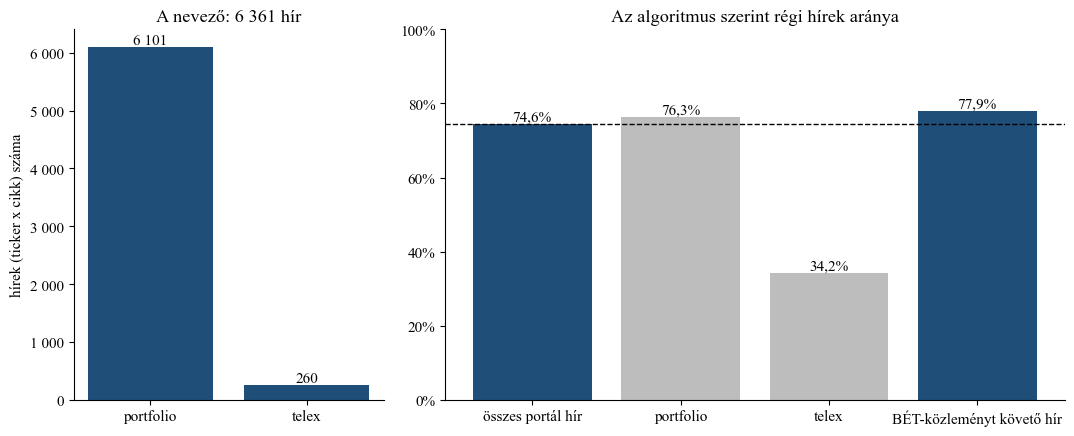

In [14]:
from matplotlib.ticker import PercentFormatter, FuncFormatter

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Liberation Serif", "Times New Roman", "DejaVu Serif"]
plt.rcParams["font.size"] = 11

KEK = "#1f4e79"
SZURKE = "#bdbdbd"

def ezres_formazo(x, pos):
    szoveg = f"{x:,.0f}"
    return szoveg.replace(",", " ")

ezres = FuncFormatter(ezres_formazo)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), width_ratios=[1, 2])

ax[0].bar(N_h.index, N_h, color=KEK)

osszes_par = f"{N_h.sum():,}".replace(",", " ")
ax[0].set_title(f"A nevező: {osszes_par} hír")
ax[0].set_ylabel("hírek (ticker x cikk) száma")
ax[0].yaxis.set_major_formatter(ezres)

for i, db in enumerate(N_h):
    felirat = f"{db:,}".replace(",", " ")
    ax[0].text(i, db, felirat, ha="center", va="bottom")

arany_adatok = {}
arany_adatok["összes portál hír"] = p_alg

forras_atlagok = alapsokasag.groupby("forras")["regi_alg"].mean()
for forras_nev, ertek in forras_atlagok.items():
    arany_adatok[forras_nev] = ertek

arany_adatok["BÉT-közleményt követő hír"] = bet_utan["regi_alg"].mean()
arany = pd.Series(arany_adatok)

szinek = []
for i in range(len(arany)):
    if i == 0 or i == len(arany) - 1:
        szinek.append(KEK)
    else:
        szinek.append(SZURKE)

ax[1].bar(arany.index, arany, color=szinek)
ax[1].axhline(p_alg, color="black", linestyle="--", linewidth=1) 

ax[1].set_title("Az algoritmus szerint régi hírek aránya")
ax[1].set_ylim(0, 1)
ax[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

for i, a in enumerate(arany):
    felirat = f"{a:.1%}".replace(".", ",")
    ax[1].text(i, a, felirat, ha="center", va="bottom")

for tengely in ax:
    tengely.grid(False)
    tengely.spines["top"].set_visible(False)
    tengely.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### 7.2 A kézi minta

400 elemű, portálonként arányosan rétegzett, visszatevés nélküli véletlen minta. A munkafüzet minden mintaelemhez tartalmazza a megelőző 72 óra összes azonos tickerű dokumentumát, az algoritmus besorolását nem. A cella csak akkor írja meg a munkafüzetet, ha az még nem létezik.

In [15]:
def mintat_vesz(pop, n_osszes, seed):
    n_h = (n_osszes * pop.groupby("forras").size() / len(pop)).round().astype(int)
    return pd.concat([pop[pop.forras == f].sample(n=n_h[f], replace=False, random_state=seed) for f in n_h.index])


minta = mintat_vesz(alapsokasag, N_MINTA, SEED).reset_index(drop=True)
minta["minta_id"] = minta.index + 1
print(f"A minta mérete: {len(minta)}, rétegenként:", minta.groupby("forras").size().to_dict())
print(f"Mintavételi arány rétegenként:", (minta.groupby("forras").size() / N_h).round(4).to_dict())

A minta mérete: 400, rétegenként: {'portfolio': 384, 'telex': 16}
Mintavételi arány rétegenként: {'portfolio': 0.0629, 'telex': 0.0615}


In [16]:
LISTAK = ticker_listak(dokok)
IDOK = {t: [d.ts for d in lista] for t, lista in LISTAK.items()}
HELY = {(d.doc_id, t): i for t, lista in LISTAK.items() for i, d in enumerate(lista)}


def ablak_cikkek(doc_id, ticker):
    return jeloltek_valasztas(LISTAK[ticker], IDOK[ticker], HELY[(doc_id, ticker)])


def munkafuzet_irasa():
    from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE

    def tiszta(ertek):
        return ILLEGAL_CHARACTERS_RE.sub("", ertek) if isinstance(ertek, str) else ertek

    sor_minta, sor_ablak = [], []
    for r in minta.itertuples():
        sor_minta.append({"minta_id": r.minta_id, "doc_id": r.doc_id, "ticker": r.ticker, "forras": r.forras,
                          "megjelenes_helyi": meta.megjelenes_helyi[r.doc_id], "cim": meta.cim[r.doc_id],
                          "lead": str(meta.lead[r.doc_id] or "")[:250], "url": meta.url[r.doc_id],
                          "ablak_db": r.jelolt_db, "kezi_regi": None, "kezi_forras_url": None, "megjegyzes": None})
        for c in sorted(ablak_cikkek(r.doc_id, r.ticker), key=lambda c: c.kulcs, reverse=True):
            sor_ablak.append({"minta_id": r.minta_id, "ticker": r.ticker, "jelolt_forras": c.forras,
                              "jelolt_megjelenes_helyi": meta.megjelenes_helyi[c.doc_id],
                              "ora_elteres": round((dokok[r.doc_id].ts - c.ts) / 3600, 1),
                              "jelolt_cim": meta.cim[c.doc_id], "jelolt_lead": str(meta.lead[c.doc_id] or "")[:250],
                              "jelolt_url": meta.url[c.doc_id]})
    with pd.ExcelWriter(VALIDACIOS_FAJL, engine="openpyxl") as iro:
        for nev, lap in {"minta": pd.DataFrame(sor_minta), "ablak": pd.DataFrame(sor_ablak)}.items():
            lap.map(tiszta).to_excel(iro, sheet_name=nev, index=False)


if VALIDACIOS_FAJL.exists():
    print("A munkafüzet már létezik, nem írom felül:", VALIDACIOS_FAJL.name)
else:
    munkafuzet_irasa()
    print("Létrehozva:", VALIDACIOS_FAJL.name)

A munkafüzet már létezik, nem írom felül: h1a_validacio.xlsx


### 7.3 A kézi címkék beolvasása

Ellenőrzés: minden elemnek van címkéje (1: régi, 0: új), a munkafüzet ehhez a mintához tartozik, a megadott forrás-url szerepel az ablakban.

In [17]:
kezi = pd.read_excel(VALIDACIOS_FAJL, sheet_name="minta")
ablak_lap = pd.read_excel(VALIDACIOS_FAJL, sheet_name="ablak")
if kezi.kezi_regi.isna().any() or not kezi.kezi_regi.isin([0, 1]).all():
    raise ValueError("A kezi_regi oszlopban minden sorban 0 vagy 1 kell")
minta = minta.merge(kezi[["minta_id", "doc_id", "ticker", "kezi_regi", "kezi_forras_url"]],
                    on=["minta_id", "doc_id", "ticker"], how="inner")
if len(minta) != N_MINTA:
    raise ValueError("A munkafüzet nem ehhez a mintához tartozik")
minta["kezi_regi"] = minta.kezi_regi.astype(int)


def url_lista(ertek):
    return [u.strip() for u in str(ertek).replace("\n", ";").split(";") if u.strip() and u.strip() != "nan"]


ervenyes = set(zip(ablak_lap.minta_id, ablak_lap.jelolt_url))
regi_cimkek = minta[minta.kezi_regi == 1]
rendben = sum(len(url_lista(r.kezi_forras_url)) > 0 and all((r.minta_id, u) in ervenyes for u in url_lista(r.kezi_forras_url))
              for r in regi_cimkek.itertuples())
print(f"Kézi címkék: {len(minta)}, ebből régi: {len(regi_cimkek)}")
print(f"Régi címkék, amelyeknél a forrás-url megvan és az ablakban szerepel: {rendben} / {len(regi_cimkek)}")

Kézi címkék: 400, ebből régi: 236
Régi címkék, amelyeknél a forrás-url megvan és az ablakban szerepel: 228 / 236


### 7.4 Tévesztési mátrix (9. táblázat)

| | kézi: régi | kézi: új |
|---|---|---|
| algoritmus: régi | TP | FP |
| algoritmus: új | FN | TN |

$\text{pontosság}=\frac{TP}{TP+FP}, \qquad \text{felidézés}=\frac{TP}{TP+FN}$

In [18]:
def tevesztes(algo, kezi_cimke):
    algo = np.asarray(algo)
    kezi_cimke = np.asarray(kezi_cimke)
    return {"TP": int(((algo == 1) & (kezi_cimke == 1)).sum()), "FP": int(((algo == 1) & (kezi_cimke == 0)).sum()),
            "FN": int(((algo == 0) & (kezi_cimke == 1)).sum()), "TN": int(((algo == 0) & (kezi_cimke == 0)).sum())}


m = tevesztes(minta.regi_alg, minta.kezi_regi)
display(pd.DataFrame([[m["TP"], m["FP"]], [m["FN"], m["TN"]]],
                     index=["algoritmus: régi", "algoritmus: új"], columns=["kézi: régi", "kézi: új"]))
pontossag = m["TP"] / (m["TP"] + m["FP"])
felidezes = m["TP"] / (m["TP"] + m["FN"])
print(f"Pontosság (precision): {pontossag:.3f}")
print(f"Felidézés (recall):    {felidezes:.3f}")
print(f"Az algoritmus a mintában {minta.regi_alg.mean():.1%}-ot, a kézi címke {minta.kezi_regi.mean():.1%}-ot jelöl réginek.")

,kézi: régi,kézi: új
algoritmus: régi,197,108
algoritmus: új,39,56


Pontosság (precision): 0.646
Felidézés (recall):    0.835
Az algoritmus a mintában 76.2%-ot, a kézi címke 59.0%-ot jelöl réginek.


### 7.5 A tévesztéssel korrigált arány, mint kontrollszámítás (12. táblázat)

$$\hat p=p_{\text{alg}}\cdot\frac{\text{pontosság}}{\text{felidézés}}$$

95%-os konfidenciaintervallum: 5 000 ismétléses, portálonként rétegzett klaszter-bootstrap, ahol a klaszter a cikk (`doc_id`) az összes ticker-párjával. Összehasonlításul a kézi címkék közvetlen aránya.

In [19]:
def klaszter_bootstrap(adat, statisztika, ismetles=BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed)
    sorok = defaultdict(list)
    for i, doc_id in enumerate(adat.doc_id.to_numpy()):
        sorok[doc_id].append(i)
    retegek = adat.groupby("forras").doc_id.unique()
    eredmeny = []
    for _ in range(ismetles):
        idx = []
        for docok in retegek:
            for doc_id in rng.choice(docok, size=len(docok), replace=True):
                idx.extend(sorok[doc_id])
        eredmeny.append(statisztika(np.array(idx)))
    return np.array(eredmeny, dtype=float)


def korrigalt_arany(algo, kezi_cimke, p):
    tp = ((algo == 1) & (kezi_cimke == 1)).sum()
    if (algo == 1).sum() == 0 or (kezi_cimke == 1).sum() == 0:
        return np.nan
    return p * (tp / (algo == 1).sum()) / (tp / (kezi_cimke == 1).sum())


def h1a_becsles(adat, p):
    algo = adat.regi_alg.to_numpy()
    kezi_cimke = adat.kezi_regi.to_numpy()
    pont = korrigalt_arany(algo, kezi_cimke, p)
    ci = np.nanpercentile(klaszter_bootstrap(adat, lambda idx: korrigalt_arany(algo[idx], kezi_cimke[idx], p)), [2.5, 97.5])
    kozvetlen_ci = np.percentile(klaszter_bootstrap(adat, lambda idx: kezi_cimke[idx].mean()), [2.5, 97.5])
    return pont, ci, kezi_cimke.mean(), kozvetlen_ci


pont, ci, kozvetlen, kozvetlen_ci = h1a_becsles(minta, p_alg)
minta_bet = minta[minta.bet_elozmeny]
pont_b, ci_b, kozvetlen_b, kozvetlen_ci_b = h1a_becsles(minta_bet, bet_utan.regi_alg.mean())

h1a_tabla = pd.DataFrame([
    {"becslés": "az algoritmus aránya (p_alg)", "nevező": "összes portálos pár", "N vagy n": len(alapsokasag),
     "régi %": 100 * p_alg, "CI alsó": np.nan, "CI felső": np.nan},
    {"becslés": "precision/recall-korrigált", "nevező": "összes portálos pár", "N vagy n": len(minta),
     "régi %": 100 * pont, "CI alsó": 100 * ci[0], "CI felső": 100 * ci[1]},
    {"becslés": "kézi címkék közvetlen aránya", "nevező": "összes portálos pár", "N vagy n": len(minta),
     "régi %": 100 * kozvetlen, "CI alsó": 100 * kozvetlen_ci[0], "CI felső": 100 * kozvetlen_ci[1]},
    {"becslés": "az algoritmus aránya (p_alg)", "nevező": "BÉT-közleményt követő pár", "N vagy n": len(bet_utan),
     "régi %": 100 * bet_utan.regi_alg.mean(), "CI alsó": np.nan, "CI felső": np.nan},
    {"becslés": "precision/recall-korrigált", "nevező": "BÉT-közleményt követő pár", "N vagy n": len(minta_bet),
     "régi %": 100 * pont_b, "CI alsó": 100 * ci_b[0], "CI felső": 100 * ci_b[1]},
    {"becslés": "kézi címkék közvetlen aránya", "nevező": "BÉT-közleményt követő pár", "N vagy n": len(minta_bet),
     "régi %": 100 * kozvetlen_b, "CI alsó": 100 * kozvetlen_ci_b[0], "CI felső": 100 * kozvetlen_ci_b[1]},
])
display(h1a_tabla.round(1))
print("Pontosság és felidézés a BÉT-közleményt követő mintaelemeken:",
      {k: round(v, 3) for k, v in zip(["precision", "recall"],
       [minta_bet[minta_bet.regi_alg == 1].kezi_regi.mean(), minta_bet[minta_bet.kezi_regi == 1].regi_alg.mean()])})

,becslés,nevező,N vagy n,régi %,CI alsó,CI felső
0,az algoritmus aránya (p_alg),összes portálos pár,6361,74.6,NaN,NaN
1,precision/recall-korrigált,összes portálos pár,400,57.7,52.8,62.9
2,kézi címkék közvetlen aránya,összes portálos pár,400,59.0,54.1,63.9
3,az algoritmus aránya (p_alg),BÉT-közleményt követő pár,3541,77.9,NaN,NaN
4,precision/recall-korrigált,BÉT-közleményt követő pár,227,58.9,52.6,65.6
5,kézi címkék közvetlen aránya,BÉT-közleményt követő pár,227,61.2,54.9,67.5


Pontosság és felidézés a BÉT-közleményt követő mintaelemeken: {'precision': np.float64(0.652), 'recall': np.float64(0.863)}


### 7.6 A régi hírek algoritmikus aránya az ablak és az Old-küszöb szerint (14. ábra)

Átvétel-küszöb: 0,80; szürke sáv: a kézi mintán mért arány 95%-os intervalluma.

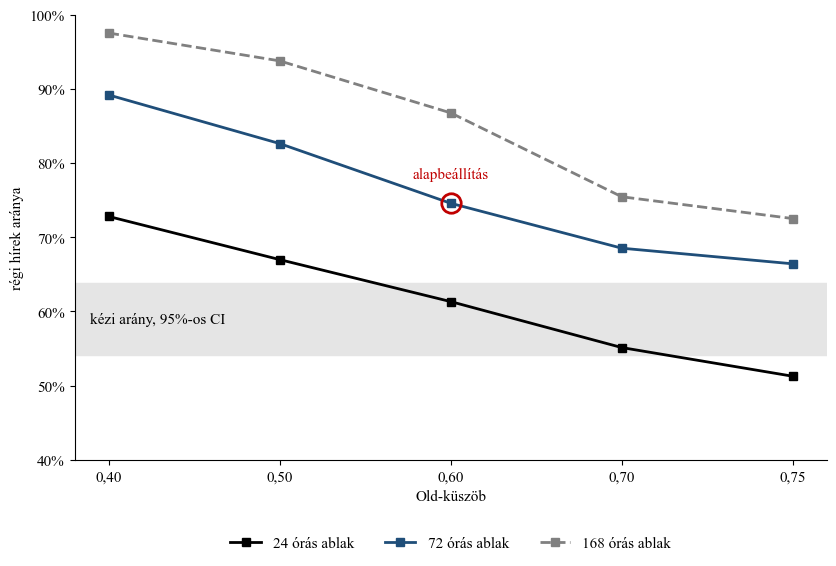

In [20]:
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"],
    "font.size": 11,
})
KEK, PIROS = "#1f4e79", "#c00000"

kezi_ci = np.asarray(kozvetlen_ci, dtype=float)

adat = racs[racs["átvétel-küszöb"] == 0.8].pivot(
    index="Old-küszöb", columns="ablak (óra)", values="régi %"
) / 100
x = np.arange(len(adat))
stilus = {
    24: dict(color="black", ls="-"),
    72: dict(color=KEK, ls="-"),
    168: dict(color="gray", ls="--"),
}
alap_x = list(adat.index).index(REGI_KUSZOB)
alap_y = adat.loc[REGI_KUSZOB, REGI_ABLAK_ORA]

fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.axhspan(kezi_ci[0], kezi_ci[1], color="#e5e5e5", zorder=0)
ax.text(
    0.02,
    kezi_ci.mean(),
    "kézi arány, 95%-os CI",
    transform=ax.get_yaxis_transform(),
    va="center",
)

for ablak in adat.columns:
    ax.plot(x, adat[ablak], marker="s", lw=2, label=f"{ablak} órás ablak", **stilus[ablak])

ax.plot(alap_x, alap_y, "o", ms=14, mfc="none", mec=PIROS, mew=2)
ax.annotate(
    "alapbeállítás",
    (alap_x, alap_y),
    xytext=(0, 18),
    textcoords="offset points",
    ha="center",
    color=PIROS,
)

ax.set_xticks(x, [f"{k:.2f}".replace(".", ",") for k in adat.index])
ax.set_ylim(0.40, 1.0)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Old-küszöb")
ax.set_ylabel("régi hírek aránya")
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

## 8. A besorolás validációja (5.2)

### 8.1 Egyezés és Cohen-kappa

$\kappa=\frac{p_o-p_e}{1-p_e}$ ($p_o$: megfigyelt, $p_e$: véletlen egyezés; Landis & Koch, 1977). Mellette szenzitivitás és specificitás, cikk×ticker páronként és egyedi cikkenként; az intervallum a 7.5 pont klaszter-bootstrapjével.

In [21]:
def egyezes_mutatok(algo, kezi_cimke):
    t = tevesztes(algo, kezi_cimke)
    n = sum(t.values())
    p_o = (t["TP"] + t["TN"]) / n
    p_e = ((t["TP"] + t["FP"]) * (t["TP"] + t["FN"]) + (t["TN"] + t["FN"]) * (t["TN"] + t["FP"])) / n ** 2
    return {"n": n, "egyezés": p_o, "kappa": (p_o - p_e) / (1 - p_e) if p_e < 1 else np.nan,
            "szenzitivitás": t["TP"] / (t["TP"] + t["FN"]), "specificitás": t["TN"] / (t["TN"] + t["FP"])}


cikkek = minta.groupby(["doc_id", "forras"], as_index=False).agg(regi_alg=("regi_alg", "max"), kezi_regi=("kezi_regi", "max"))
sorok = []
for nev, adat in [("cikk×ticker pár", minta), ("egyedi cikk", cikkek)]:
    algo, kezi_cimke = adat.regi_alg.to_numpy(), adat.kezi_regi.to_numpy()
    e = egyezes_mutatok(algo, kezi_cimke)
    ci = np.nanpercentile(klaszter_bootstrap(adat, lambda idx: egyezes_mutatok(algo[idx], kezi_cimke[idx])["kappa"]), [2.5, 97.5])
    sorok.append({"szint": nev, **e, "kappa CI": f"[{ci[0]:.2f}; {ci[1]:.2f}]"})
display(pd.DataFrame(sorok).set_index("szint").round(3))

,n,egyezés,kappa,szenzitivitás,specificitás,kappa CI
szint,,,,,,
cikk×ticker pár,400,0.632,0.188,0.835,0.341,[0.10; 0.28]
egyedi cikk,373,0.633,0.180,0.834,0.333,[0.08; 0.27]


### 8.2 Old-küszöb és alcsoportok (10–11. táblázat)

Kappa a csak szövegből számolt Old különböző küszöbeinél; az algoritmus és a kézi címke régi aránya cikkhossz, portál és hivatkozás szerint.

In [22]:
x = minta.dropna(subset=["regi_arany"])
sorok = []
for k in [0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9]:
    tipp = (x.regi_arany >= k).astype(int)
    e = egyezes_mutatok(tipp, x.kezi_regi)
    sorok.append({"Old-küszöb": k, "algoritmus régi %": 100 * tipp.mean(), "egyezés": e["egyezés"], "kappa": e["kappa"]})
display(pd.DataFrame(sorok).set_index("Old-küszöb").round(3))

csoport = minta.assign(
    hossz=pd.cut(minta.szoveg_db, bins=[0, 100, 300, np.inf], labels=["<=100 szótő", "101-300 szótő", ">300 szótő"]),
    hivatkozas=np.where(minta.hivatkozott == "[]", "nincs", "van"),
    egyezik=(minta.regi_alg == minta.kezi_regi).astype(int))
for oszlop in ["hossz", "forras", "hivatkozas"]:
    tabla = csoport.groupby(oszlop, observed=True).agg(
        n=("kezi_regi", "size"), algoritmus_regi=("regi_alg", "mean"), kezi_regi=("kezi_regi", "mean"), egyezes=("egyezik", "mean"))
    tabla[["algoritmus_regi", "kezi_regi", "egyezes"]] *= 100
    display(tabla.round(1))

,algoritmus régi %,egyezés,kappa
Old-küszöb,,,
0.40,88.50,0.610,0.094
0.50,78.25,0.592,0.093
0.60,69.50,0.585,0.107
0.70,61.50,0.560,0.082
0.75,59.50,0.555,0.078
0.80,55.25,0.532,0.047
0.90,32.00,0.480,0.023


,n,algoritmus_regi,kezi_regi,egyezes
hossz,,,,
<=100 szótő,253,94.5,60.9,63.2
101-300 szótő,38,65.8,39.5,63.2
>300 szótő,109,37.6,61.5,63.3


,n,algoritmus_regi,kezi_regi,egyezes
forras,,,,
portfolio,384,78.1,59.4,63.0
telex,16,31.2,50.0,68.8


,n,algoritmus_regi,kezi_regi,egyezes
hivatkozas,,,,
nincs,352,73.0,55.4,60.2
van,48,100.0,85.4,85.4


### 8.3 Az átfedésmérők szétválasztó ereje (AUC)

Az AUC rangokból számolva (az egyező értékek fél pontot kapnak); 0,5 a véletlen, 1 a tökéletes szétválasztás.

| mérték | mit mér |
|---|---|
| Old | az alapalgoritmus mértéke |
| IDF-súlyozott Old | szótősúly $\ln\big(N/(1+df_w)\big)$; az öt szomszéd is a súlyozott átfedés alapján |
| csak számok fedése | a cikk számainak (IDF-súlyozott) hányada, amely az ablak valamely korábbi dokumentumában is szerepel |

In [23]:
def auc(pontszam, kezi_cimke):
    pontszam = np.asarray(pontszam, dtype=float)
    kezi_cimke = np.asarray(kezi_cimke)
    n_regi, n_uj = (kezi_cimke == 1).sum(), (kezi_cimke == 0).sum()
    if n_regi == 0 or n_uj == 0:
        return np.nan
    return (rankdata(pontszam)[kezi_cimke == 1].sum() - n_regi * (n_regi + 1) / 2) / (n_regi * n_uj)


def suly_osszeg(szavak, sulyok):
    return sum(sulyok.get(w, 0.0) for w in szavak)


df_szo = Counter()
for d in dokok.values():
    df_szo.update(d.szavak)
idf = {w: max(0.0, math.log(len(dokok) / (1 + db))) for w, db in df_szo.items()}


def old_idf(s, jeloltek):
    nevezo = suly_osszeg(s.szavak, idf)
    pontok = sorted(((suly_osszeg(s.szavak & c.szavak, idf), c.kulcs, s.szavak & c.szavak) for c in jeloltek if s.szavak & c.szavak),
                    key=lambda p: (p[0], p[1]), reverse=True)[:REGI_SZOMSZED_DB]
    unio = set().union(*[p[2] for p in pontok]) if pontok else set()
    return suly_osszeg(unio, idf) / nevezo if nevezo > 0 else np.nan


SZAM = re.compile(r"\d{1,3}(?:[ \u00a0]\d{3})+(?:,\d+)?|\d+(?:[.,]\d+)?")
SZO = re.compile(r"[^\W\d_]+|[.!?]")
SAJAT_NEVEK = CEGNEVEK | frozenset(["magyar", "gedeon", "nyrt", "bank", "budapesti"])


def kulcs_tokenek(cim, lead, torzs):
    szoveg = f"{cim or ''}. {lead or ''}. {torzs or ''}"
    szamok = {"#" + t for t in (m.group(0).replace(" ", "").replace("\u00a0", "").replace(",", ".") for m in SZAM.finditer(szoveg)) if len(t) >= 2}
    nevek, mondat_eleje = set(), True
    for w in SZO.findall(szoveg):
        if w in ".!?":
            mondat_eleje = True
            continue
        if w[0].isupper() and not mondat_eleje and len(w) >= 3 and w.lower() not in SAJAT_NEVEK:
            nevek.add("@" + TOVEZO.stemWord(w.lower()))
        mondat_eleje = False
    return frozenset(szamok), frozenset(nevek)


szukseges = set(minta.doc_id) | {c.doc_id for r in minta.itertuples() for c in ablak_cikkek(r.doc_id, r.ticker)}
con = db_kapcsolat()
kulcsok = {}
for sor in con.execute(f"SELECT doc_id, forras, cim, lead, szoveg FROM dokumentum WHERE doc_id IN ({','.join('?' * len(szukseges))})", list(szukseges)):
    torzs = KÖ.bet_szoveg_tisztit(sor["szoveg"]) if sor["forras"] == "bet" else sor["szoveg"]
    kulcsok[sor["doc_id"]] = kulcs_tokenek(sor["cim"], sor["lead"], torzs)
con.close()
kulcs_df = Counter()
for szamok, nevek in kulcsok.values():
    kulcs_df.update(szamok | nevek)
kulcs_idf = {t: max(0.0, math.log(len(kulcsok) / (1 + db))) for t, db in kulcs_df.items()}


def kulcs_fedes(doc_id, ticker, csak_szam):
    szamok, nevek = kulcsok[doc_id]
    sajat = szamok if csak_szam else szamok | nevek
    elozmeny = set()
    for c in ablak_cikkek(doc_id, ticker):
        cs, cn = kulcsok[c.doc_id]
        elozmeny |= cs if csak_szam else cs | cn
    nevezo = suly_osszeg(sajat, kulcs_idf)
    return suly_osszeg(sajat & elozmeny, kulcs_idf) / nevezo if nevezo > 0 else np.nan


merok = pd.DataFrame({
    "Old": minta.regi_arany,
    "IDF-súlyozott Old": [old_idf(dokok[r.doc_id], ablak_cikkek(r.doc_id, r.ticker)) for r in minta.itertuples()],
    "csak számok fedése": [kulcs_fedes(r.doc_id, r.ticker, True) for r in minta.itertuples()],
})

sorok = []
for nev in merok.columns:
    van = merok[nev].notna().to_numpy()
    adat = minta[van].reset_index(drop=True)
    p, k = merok[nev][van].to_numpy(), adat.kezi_regi.to_numpy()
    ci = np.nanpercentile(klaszter_bootstrap(adat, lambda idx: auc(p[idx], k[idx])), [2.5, 97.5])
    sorok.append({"mérték": nev, "n": len(adat), "AUC": auc(p, k), "CI alsó": ci[0], "CI felső": ci[1]})
auc_tabla = pd.DataFrame(sorok).set_index("mérték").round(3)
display(auc_tabla)

,n,AUC,CI alsó,CI felső
mérték,,,,
Old,400,0.540,0.479,0.597
IDF-súlyozott Old,400,0.540,0.479,0.598
csak számok fedése,399,0.583,0.526,0.639


### 8.4 A kézzel megjelölt forrásból átvett hányad

A régi címkéknél megadott források közül a legtöbbet tartalmazott forrás szótöveinek hányada, amely a cikkben is szerepel.

In [24]:
url_doc = {url: doc_id for doc_id, url in meta.url.items()}
ertekek = []
for r in minta[minta.kezi_regi == 1].itertuples():
    s = dokok[r.doc_id].szavak
    forrasok = [dokok[url_doc[u]].szavak for u in url_lista(r.kezi_forras_url) if url_doc.get(u) in dokok]
    forrasok = [f for f in forrasok if len(f) > 0]
    if forrasok:
        ertekek.append(max(len(s & f) / len(f) for f in forrasok))
ertekek = pd.Series(ertekek)
print(f"Számolható régi címkék: {len(ertekek)}")
print(f"A forrás szótöveinek átlagosan {ertekek.mean():.1%}-át tartalmazza a cikk (medián {ertekek.median():.1%})")
print(f"A forrás legalább 80%-át tartalmazza: {(ertekek >= 0.8).mean():.1%}")

Számolható régi címkék: 228
A forrás szótöveinek átlagosan 52.2%-át tartalmazza a cikk (medián 60.3%)
A forrás legalább 80%-át tartalmazza: 2.6%
